In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from registry import build_model
from utils.trainer_utils import (
    make_burgers2d_data,
    evaluate_model_on_inner_grid,
    relative_l2_error,
)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = [1, 2, 3, 4, 5]
H_X = H_Y = H_T = 1.0 / 20.0
U_LEFT, U_MIDDLE, U_RIGHT = 1.0, 0.6, 0.0
DISCONTINUITY_DISTANCE = 0.8
SHARP_CONST = 1.0
SAVE_ALL_TIMES = False
TARGET_TIMES = [0.0, 0.25, 0.5, 0.75, 1.0]
PRED_VMIN = PRED_VMAX = None
ERROR_VMIN, ERROR_VMAX = 0.0, None
output_root = Path("evaluation/burgers2d")
OUTPUT_DIR = output_root

METHODS = {
    "Conventional": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_conventional(burgers2d)",
    },
    "SA": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_SA(burgers2d)",
    },
    "NTK": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_NTK(burgers2d)",
    },
    "aSA": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_aSA(burgers2d)",
    },
    "Causal": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_causal(burgers2d)",
    },
    "rba": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_rba(burgers2d)",
    },
    "brdr": {
        "model_name": "PINN",
        "layers": [3, 200, 200, 200, 200, 200, 1],
        "activation": "Tanh",
        "checkpoint_root": "runs/burgers2d/results_brdr(burgers2d)",
    },
    "SLFormer_Single(NoSlope)": {
        "model_name": "Burgers2DSLSingleFormer_NoSlope",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "SiLU",
        "checkpoint_root": "runs/burgers2d/results_single_NoSlope(burgers2d)",
    },
    "SLFormer(NoSlope)": {
        "model_name": "Burgers2DSLFormer_NoSlope",
        "embed_dim": 64,
        "num_heads": 1,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "SiLU",
        "checkpoint_root": "runs/burgers2d/results_multi_NoSlope(burgers2d)",
    },
    "SLFormer": {
        "model_name": "Burgers2DSLFormerFixedSharpAnalysis",
        "embed_dim": 64,
        "num_heads": 2,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "SiLU",
        "checkpoint_root": "runs/burgers2d/results_multi(burgers2d)",
    },
    "SLFormer_Single": {
        "model_name": "Burgers2DSLSingleFormerAnalysis",
        "embed_dim": 64,
        "num_heads": 2,
        "depth": 2,
        "fourier_scale": 0.25,
        "activation": "SiLU",
        "checkpoint_root": "runs/burgers2d/results_single(burgers2d)",
    },
}

def build_args(cfg):
    defaults = dict(
        activation="Tanh", fourier_scale=0.25,
        embed_dim=64, num_heads=2, depth=2, dropout=0.0,
        use_qk_norm=True, learnable_temperature=False,
        layerscale_init=1.0e-2, num_frequencies=10,
        period=1.0, use_weight_norm=False,
    )
    defaults.update({k: v for k, v in cfg.items() if k != "checkpoint_root"})
    args = SimpleNamespace(**defaults)
    args.eval_h_x, args.eval_h_y, args.eval_h_t = H_X, H_Y, H_T
    args.no_sharp_const = False
    args.sharp_const = cfg.get("sharp_const", SHARP_CONST)
    return args

print("Device:", device)


Device: cuda


In [3]:
"""Shared output contract for time-resolved PDE shock metrics."""
SHOCK_BRANCH_ORDER = {'combined': 0, 'shock1': 1, 'shock2': 2}
SHOCK_SUMMARY_METRICS = ['line_length', 'sample_count', 'detected_samples', 'detection_rate', 'location_mae', 'location_rmse', 'location_max', 'multiple_crossing_rate', 'width_valid_samples', 'width_valid_rate', 'width_mean', 'width_max', 'width_underresolved_rate', 'window_underresolved_rate', 'shock_band_rmse', 'shock_band_point_count', 'shock_band_point_fraction', 'shock_band_geometry_error_bound']
SHOCK_DISPLAY_COLUMNS = ['method', 'branch', 'requested_time', 'time', 'location_mae_mean', 'location_mae_std', 'location_rmse_mean', 'location_rmse_std', 'width_mean_mean', 'width_mean_std', 'detection_rate_mean', 'width_valid_rate_mean', 'shock_band_rmse_mean', 'shock_band_rmse_std', 'shock_band_point_count_mean']

def shock_band_metrics(error, mask, geometry_error=0.0):
    """Pointwise RMSE on a fixed exact-front band; empty masks remain NaN."""
    count = int(mask.sum())
    return {'shock_band_rmse': float(np.sqrt(np.mean(error[mask] ** 2))) if count else np.nan, 'shock_band_point_count': count, 'shock_band_point_fraction': float(mask.mean()), 'shock_band_geometry_error_bound': float(geometry_error)}

def sort_shock_rows(frame, time_column='time'):
    """Sort by time, then combined, shock1, shock2."""
    return frame.assign(_branch_order=frame['branch'].map(SHOCK_BRANCH_ORDER)).sort_values([time_column, '_branch_order']).drop(columns='_branch_order').reset_index(drop=True)

def plot_shock_metrics(frame, save_path, aggregated=False):
    """Use the same panel order, labels and rendering for every PDE."""
    fig, axes = plt.subplots(1, 4, figsize=(20, 4), dpi=180)
    suffix = '_mean' if aggregated else ''
    labels = ['Normal shock location MAE', '10-90% normal transition width', 'Measured arc-length fraction', 'Shock-band RMSE']
    groups = frame.groupby('method', sort=False) if aggregated else frame.groupby('branch', sort=False)
    for label, group in groups:
        group = group.sort_values('time')
        axes[0].plot(group['time'], group['location_mae' + suffix], label=label)
        axes[1].plot(group['time'], group['width_mean' + suffix], label=label)
        axes[2].plot(group['time'], group['detection_rate' + suffix], label=f'{label} detection')
        axes[2].plot(group['time'], group['width_valid_rate' + suffix], '--', label=f'{label} width-valid')
        axes[3].plot(group['time'], group['shock_band_rmse' + suffix], label=label)
    axes[2].set_ylim(-0.03, 1.03)
    for axis, label in zip(axes, labels):
        axis.set_xlabel('t')
        axis.set_ylabel(label + (' (seed mean)' if aggregated else ''))
        axis.grid(alpha=0.2)
        axis.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(save_path)
    plt.close(fig)

def save_shock_seed_outputs(details, summary, save_dir, settings):
    """Save the same per-seed file names and schema for every PDE."""
    folder = Path(save_dir) / 'shock_lines'
    folder.mkdir(parents=True, exist_ok=True)
    summary = sort_shock_rows(summary)
    details.to_csv(folder / 'shock_line_details.csv', index=False)
    summary.to_csv(folder / 'shock_line_timewise.csv', index=False)
    (folder / 'shock_line_settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
    plot_shock_metrics(summary, folder / 'shock_line_timewise.png')
    return summary

def summarize_shock_results(shock_timewise_by_method, output_root, target_times):
    """Aggregate seeds at each time separately; never average over time."""
    all_records = []
    all_summaries = []
    for method_name, frames in shock_timewise_by_method.items():
        if not frames:
            continue
        method_dir = Path(output_root) / method_name
        method_dir.mkdir(parents=True, exist_ok=True)
        records = pd.concat(frames, ignore_index=True)
        records.to_csv(method_dir / 'shock_line_seed_timewise.csv', index=False)
        keys = ['method', 'branch', 'time_index', 'time']
        summary = records.groupby(keys, sort=False)[SHOCK_SUMMARY_METRICS].agg(['mean', 'std', 'count'])
        summary.columns = [f'{metric}_{stat}' for metric, stat in summary.columns]
        summary = sort_shock_rows(summary.reset_index())
        summary.to_csv(method_dir / 'shock_line_summary_timewise.csv', index=False)
        selected = []
        available = np.sort(summary['time'].unique())
        for requested_time in target_times:
            actual_time = available[np.argmin(np.abs(available - requested_time))]
            selected.append(summary.loc[summary['time'] == actual_time].assign(requested_time=requested_time))
        target_table = sort_shock_rows(pd.concat(selected, ignore_index=True), 'requested_time')
        target_table.to_csv(method_dir / 'shock_line_summary_target_times.csv', index=False)
        print(f'\nShock-line metrics (each time separately): {method_name}')
        print(target_table[SHOCK_DISPLAY_COLUMNS].to_string(index=False, float_format=lambda value: f'{value:.6e}', na_rep='-'))
        all_records.append(records)
        all_summaries.append(summary)
    if all_records:
        pd.concat(all_records, ignore_index=True).to_csv(Path(output_root) / 'shock_line_all_methods_timewise.csv', index=False)
        comparison = pd.concat(all_summaries, ignore_index=True)
        comparison.to_csv(Path(output_root) / 'shock_line_comparison_timewise.csv', index=False)
        plot_shock_metrics(comparison.loc[comparison['branch'] == 'combined'], Path(output_root) / 'shock_line_comparison.png', aggregated=True)
    return pd.concat(all_summaries, ignore_index=True) if all_summaries else pd.DataFrame()


In [4]:
"""Time-resolved planar shock-line metrics for scalar 2D Burgers."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
SHOCK_POINTS_PER_FRONT = 64
SHOCK_NORMAL_SAMPLES = 401
SHOCK_MAX_NORMAL_DISTANCE = 0.2
SHOCK_WINDOW_FRACTION = 0.95
SHOCK_MIN_WIDTH_CELLS = 4
SHOCK_BAND_HALF_WIDTH = 0.05

def shock2d_numpy(a):
    return a.detach().cpu().numpy() if hasattr(a, 'detach') else np.asarray(a)

def shock2d_grid(coords, values):
    c = shock2d_numpy(coords).reshape(-1, 3)
    v = shock2d_numpy(values).reshape(-1)
    axes = [np.unique(c[:, j]).astype(float) for j in range(3)]
    if np.prod([len(a) for a in axes]) != len(c) or len(v) != len(c):
        raise ValueError('Expected complete physical Cartesian grid and scalar output')
    order = np.lexsort((c[:, 2], c[:, 1], c[:, 0]))
    expected = np.stack(np.meshgrid(*axes, indexing='ij'), axis=-1).reshape(-1, 3)
    if not np.allclose(c[order], expected):
        raise ValueError('Invalid physical grid')
    return (*axes, v[order].reshape(*[len(a) for a in axes]).astype(float))

def shock2d_crossings(s, u, level):
    z = u - level
    nz = np.flatnonzero(z != 0)
    roots = []
    for i, j in zip(nz[:-1], nz[1:]):
        if z[i] > 0 and z[j] < 0:
            roots.append((s[i + 1] + s[j - 1]) / 2 if j > i + 1 else s[i] - z[i] * (s[j] - s[i]) / (z[j] - z[i]))
    return np.asarray(roots)

def shock2d_summary(frame):
    total = float(frame.line_weight.sum()) if len(frame) else 0.0
    detected = frame[frame.detected] if len(frame) else frame
    widths = frame[frame.width_valid] if len(frame) else frame

    def avg(f, key):
        return float(np.average(f[key], weights=f.line_weight)) if len(f) else np.nan
    return dict(line_length=total, sample_count=len(frame), detected_samples=len(detected), width_valid_samples=len(widths), detection_rate=float(detected.line_weight.sum() / total) if total else np.nan, width_valid_rate=float(widths.line_weight.sum() / total) if total else np.nan, location_mae=avg(detected, 'location_error'), location_rmse=float(np.sqrt(avg(detected.assign(squared=detected.location_error ** 2), 'squared'))) if len(detected) else np.nan, location_max=float(detected.location_error.max()) if len(detected) else np.nan, width_mean=avg(widths, 'width'), width_max=float(widths.width.max()) if len(widths) else np.nan, multiple_crossing_rate=avg(frame.assign(multiple=(frame.midpoint_crossings > 1).astype(float)), 'multiple') if len(frame) else np.nan, width_underresolved_rate=avg(widths, 'width_underresolved'), window_underresolved_rate=avg(frame, 'window_underresolved'))

def burgers2d_band_mask(x, y, eta, half_width):
    """Euclidean distance to the exact interior line segment in [0,1]^2."""
    root2 = np.sqrt(2.0)
    half_length = min(eta, root2 - eta)
    if half_length <= 1e-10:
        return np.zeros((len(x), len(y)), dtype=bool)
    X, Y = np.meshgrid(x, y, indexing='ij')
    eta_grid = (X + Y) / root2
    xi_grid = (X - Y) / root2
    closest_xi = np.clip(xi_grid, -half_length, half_length)
    distance = np.sqrt((eta_grid - eta) ** 2 + (xi_grid - closest_xi) ** 2)
    return distance <= half_width

def measure_burgers2d_shocks(x, y, t, pred, ref, states=(1.0, 0.6, 0.0), distance=0.8):
    x, y, t = [np.asarray(a, float) for a in (x, y, t)]
    pred = np.asarray(pred, float)
    ref = np.asarray(ref, float)
    if pred.shape != (len(x), len(y), len(t)) or ref.shape != pred.shape or (not np.isfinite(pred).all()):
        raise ValueError('Invalid 2D solution arrays')
    if min(len(x), len(y)) < 3 or not all((np.all(np.diff(a) > 0) for a in (x, y, t))):
        raise ValueError('Need increasing spatial/time axes')
    if not np.allclose([x[0], x[-1], y[0], y[-1]], [0, 1, 0, 1], atol=1e-06):
        raise ValueError('This exact benchmark is defined on [0,1]^2')
    if SHOCK_POINTS_PER_FRONT < 2 or SHOCK_NORMAL_SAMPLES < 3:
        raise ValueError('Insufficient sampling points')
    if not 0 < SHOCK_WINDOW_FRACTION < 1 or SHOCK_MAX_NORMAL_DISTANCE <= 0:
        raise ValueError('Invalid normal window')
    if not np.isfinite(SHOCK_BAND_HALF_WIDTH) or SHOCK_BAND_HALF_WIDTH <= 0:
        raise ValueError('SHOCK_BAND_HALF_WIDTH must be finite and positive.')
    left, middle, right = states
    if not left > middle > right or distance <= 0:
        raise ValueError('Expected descending states and positive distance')
    root2 = np.sqrt(2.0)
    speeds = [(left + middle) / root2, (middle + right) / root2]
    if distance - (speeds[0] - speeds[1]) * t[-1] <= 0:
        raise ValueError('This formula requires noninteracting fronts')
    h = max(float(np.max(np.diff(x))), float(np.max(np.diff(y))))
    X, Y = np.meshgrid(x, y, indexing='ij')
    eta_grid = (X + Y) / root2
    details = []
    summary = []
    for k, time in enumerate(t):
        fronts = [speeds[0] * time, distance + speeds[1] * time]
        expected = np.where(eta_grid < fronts[0], left, np.where(eta_grid > fronts[1], right, middle))
        away = (abs(eta_grid - fronts[0]) > 2 * h) & (abs(eta_grid - fronts[1]) > 2 * h)
        if away.any() and (not np.allclose(ref[:, :, k][away], expected[away], atol=1e-05, rtol=1e-05)):
            raise ValueError('Reference does not match the assumed diagonal Burgers2D shock solution')
        interp = RegularGridInterpolator((x, y), pred[:, :, k], method='linear', bounds_error=True)
        band_masks = [burgers2d_band_mask(x, y, eta, SHOCK_BAND_HALF_WIDTH) for eta in fronts]
        field_error = pred[:, :, k] - ref[:, :, k]
        time_rows = []
        for j, (eta, high, low) in enumerate(zip(fronts, [left, middle], [middle, right]), 1):
            half = min(eta, root2 - eta)
            rows = []
            if half > 1e-10:
                count = int(SHOCK_POINTS_PER_FRONT)
                xis = -half + (np.arange(count) + 0.5) * (2 * half / count)
                points = np.column_stack(((eta + xis) / root2, (eta - xis) / root2))
                maxs = root2 * np.minimum(1 - points[:, 0], 1 - points[:, 1])
                mins = -root2 * np.minimum(points[:, 0], points[:, 1])
                split = abs(fronts[1] - fronts[0]) / 2
                for m, (xi, point, a, b) in enumerate(zip(xis, points, mins, maxs)):
                    start = SHOCK_WINDOW_FRACTION * max(a, -split)
                    end = SHOCK_WINDOW_FRACTION * min(b, split)
                    search_start = max(start, -SHOCK_MAX_NORMAL_DISTANCE)
                    search_end = min(end, SHOCK_MAX_NORMAL_DISTANCE)
                    s = np.unique(np.r_[np.linspace(start, end, int(SHOCK_NORMAL_SAMPLES)), 0.0])
                    positions = point[None, :] + s[:, None] / root2
                    values = interp(positions)
                    midpoint = shock2d_crossings(s, values, (high + low) / 2)
                    midpoint = midpoint[(midpoint >= search_start) & (midpoint <= search_end)]
                    row = dict(time_index=k, time=float(time), branch=f'shock{j}', point_index=m, xi=float(xi), exact_eta=float(eta), exact_x=point[0], exact_y=point[1], line_weight=2 * half / count, high_state=high, low_state=low, detected=False, midpoint_crossings=len(midpoint), normal_offset=np.nan, prediction_x=np.nan, prediction_y=np.nan, location_error=np.nan, width=np.nan, width_valid=False, width_start=np.nan, width_end=np.nan, width_underresolved=False, window_underresolved=bool(end - start < SHOCK_MIN_WIDTH_CELLS * h), window_start=start, window_end=end, status='midpoint_missing')
                    if len(midpoint):
                        offset = float(midpoint[np.argmin(abs(midpoint))])
                        before = shock2d_crossings(s, values, low + 0.9 * (high - low))
                        before = before[before < offset]
                        after = shock2d_crossings(s, values, low + 0.1 * (high - low))
                        after = after[after > offset]
                        valid = bool(len(before) and len(after))
                        width = float(after.min() - before.max()) if valid else np.nan
                        row.update(detected=True, normal_offset=offset, location_error=abs(offset), prediction_x=point[0] + offset / root2, prediction_y=point[1] + offset / root2, width=width, width_valid=valid, width_start=float(before.max()) if valid else np.nan, width_end=float(after.min()) if valid else np.nan, width_underresolved=bool(valid and width < SHOCK_MIN_WIDTH_CELLS * h), status='ok' if valid else 'width_threshold_missing')
                    rows.append(row)
            details.extend(rows)
            time_rows.extend(rows)
            frame = pd.DataFrame(rows)
            summary.append(dict(time_index=k, time=float(time), branch=f'shock{j}', status='interior_line' if rows else 'no_interior_line', **shock2d_summary(frame), **shock_band_metrics(field_error, band_masks[j - 1])))
        summary.append(dict(time_index=k, time=float(time), branch='combined', status='length_weighted', **shock2d_summary(pd.DataFrame(time_rows)), **shock_band_metrics(field_error, band_masks[0] | band_masks[1])))
    return (pd.DataFrame(details), pd.DataFrame(summary))

def save_burgers2d_shock_metrics(coords, u_pred, u_ref, save_dir, states, distance):
    x, y, t, pred = shock2d_grid(coords, u_pred)
    _, _, _, ref = shock2d_grid(coords, u_ref)
    details, summary = measure_burgers2d_shocks(x, y, t, pred, ref, states, distance)
    settings = dict(shock_band_half_width=SHOCK_BAND_HALF_WIDTH, shock_band='Euclidean distance to domain-clipped exact interior line segment; combined is mask union', shock_band_rmse='sqrt(mean((prediction-reference)^2)) on masked existing Cartesian grid nodes; not relative L2', shock_band_missing='no interior line or empty band -> NaN RMSE and zero count; independent of shock detection', shock_band_geometry_error_bound=0.0, points_per_front=SHOCK_POINTS_PER_FRONT, normal_samples=SHOCK_NORMAL_SAMPLES, max_normal_distance=SHOCK_MAX_NORMAL_DISTANCE, window_fraction=SHOCK_WINDOW_FRACTION, minimum_width_cells=SHOCK_MIN_WIDTH_CELLS, states=list(states), distance=distance, hx=float(np.max(np.diff(x))), hy=float(np.max(np.diff(y))), aggregation='each time separately; arc-length midpoint quadrature, combined weighted by line length', prediction='bilinear interpolation of unchanged Cartesian model predictions; no model re-query', position='absolute normal distance to exact line; exact width zero', missing='conditional means; detection and width-valid length fractions reported')
    return save_shock_seed_outputs(details, summary, save_dir, settings)


In [5]:
def save_surface_figure(method_name, seed, time_value, x_i, y_i, pred_i, save_dir, verbose=True):

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True,)

    fig = plt.figure(figsize=(6.0, 5.0), dpi=300)
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        x_i,
        y_i,
        pred_i,
        cmap="viridis",
        linewidth=0,
        antialiased=True,
    )

    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)

    x_ticks = np.arange(0.0, 1.01, 0.10)
    y_ticks = np.arange(0.0, 1.01, 0.10)
    ax.set_xticks(x_ticks)
    ax.set_yticks(y_ticks)
    ax.set_xticklabels(
        [
            "0.0"
            if np.isclose(x, 0.0)
            else "0.5"
            if np.isclose(x, 0.5)
            else "1.0"
            if np.isclose(x, 1.0)
            else ""
            for x in x_ticks
        ],
        fontsize=18,
    )

    ax.set_yticklabels(
        [
            "0.0"
            if np.isclose(y, 0.0)
            else "0.5"
            if np.isclose(y, 0.5)
            else "1.0"
            if np.isclose(y, 1.0)
            else ""
            for y in y_ticks
        ],
        fontsize=18,
    )
    plt.tick_params(axis="z", pad=8, labelsize=18)

    ax.set_xlabel("x", fontsize=18, labelpad=10)
    ax.set_ylabel("y", fontsize=18, labelpad=11)
    ax.set_zlabel("u", fontsize=18, labelpad=12)

    ax.view_init(elev=28, azim=120)

    time_tag = (
        f"{time_value:.6f}"
        .replace(
            ".",
            "p",
        )
    )

    save_path = (
        save_dir
        / (
            f"{method_name}"
            f"_seed{seed}"
            f"_t{time_tag}.png"
        )
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches =0.25,
    )

    plt.close(fig)

    if verbose:
        print(f"[Saved] {save_path}")


In [6]:
def save_surface(x_grid, y_grid, value, save_path, title, z_label, cmap="viridis", vmin=None, vmax=None):
    fig = plt.figure(figsize=(6, 5), dpi=300)
    ax = fig.add_subplot(111, projection="3d")
    surface = ax.plot_surface(x_grid, y_grid, value, cmap=cmap, linewidth=0, antialiased=False, vmin=vmin, vmax=vmax)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.view_init(elev=28, azim=120)
    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

def save_contour(x_grid, y_grid, value, save_path, title, colorbar_label, cmap="viridis", vmin=None, vmax=None):
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    contour = ax.contourf(x_grid, y_grid, value, levels=100, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


In [7]:
def save_seed_outputs(method_name, seed, coords, u_pred, u_ref, save_dir):

    coords_cpu = coords.detach().cpu()
    axes = [torch.unique(coords_cpu[..., j], sorted=True) for j in range(3)]
    nx, ny, nt = [len(axis) for axis in axes]
    if coords_cpu.numel() != nx * ny * nt * 3:
        raise ValueError("Evaluation coordinates are not a complete Cartesian grid.")
    coords_grid = coords_cpu.reshape(nx, ny, nt, 3)
    expected = torch.stack(torch.meshgrid(*axes, indexing="ij"), dim=-1)
    if not torch.allclose(coords_grid, expected):
        raise ValueError("Expected coordinate ordering: meshgrid(x, y, t, indexing='ij').")
    pred_grid = u_pred.detach().cpu().reshape(nx, ny, nt)
    ref_grid = u_ref.detach().cpu().reshape(nx, ny, nt)
    diff = pred_grid - ref_grid
    time_values = axes[2].numpy()
    metrics_df = pd.DataFrame({
        "time_index": np.arange(nt),
        "time": time_values,
        "relative_l2_error": [float(torch.linalg.vector_norm(diff[:, :, i]) /
            (torch.linalg.vector_norm(ref_grid[:, :, i]) + 1.0e-12)) for i in range(nt)],
        "absolute_l2_error": [float(torch.linalg.vector_norm(diff[:, :, i])) for i in range(nt)],
        "max_absolute_error": [float(diff[:, :, i].abs().max()) for i in range(nt)],
    })
    metrics_df.to_csv(save_dir / "timewise_errors.csv", index=False)
    time_indices = list(range(nt)) if SAVE_ALL_TIMES else sorted({
        int(np.argmin(np.abs(time_values - t))) for t in TARGET_TIMES
    })
    for i in time_indices:
        time_value = float(time_values[i])
        x_i = coords_grid[:, :, i, 0].numpy()
        y_i = coords_grid[:, :, i, 1].numpy()
        pred_i = pred_grid[:, :, i].numpy()
        ref_i = ref_grid[:, :, i].numpy()
        error_i = diff[:, :, i].abs().numpy()
        tag = f"t{i:04d}_{time_value:.6f}".replace(".", "p")

        for name, values, cmap, vmin, vmax in [
            ("prediction", pred_i, "viridis", PRED_VMIN, PRED_VMAX),
            ("reference", ref_i, "viridis", PRED_VMIN, PRED_VMAX),
            ("error", error_i, "magma", ERROR_VMIN, ERROR_VMAX),
        ]:
            for kind, plotter in [("surface", save_surface), ("contour", save_contour)]:
                directory = save_dir / f"{name}_{kind}"
                directory.mkdir(parents=True, exist_ok=True)

                if kind == "surface" and name in {"prediction", "reference"}:
                    save_surface_figure(
                        method_name, seed, time_value,
                        x_i, y_i, values,
                        save_dir=directory,
                        verbose=(name == "prediction"),
                    )
                else:
                    plotter(
                        x_i, y_i, values,
                        directory / f"{name}_{kind}_{tag}.png",
                        f"{name.capitalize()} at t={time_value:.4f}",
                        "|u_pred-u_ref|" if name == "error" else "u",
                        cmap, vmin, vmax,
                    )
    fig, ax = plt.subplots(figsize=(7, 4.5), dpi=300)
    ax.plot(time_values, metrics_df["relative_l2_error"], linewidth=2.2)
    ax.set_xlabel("Time")
    ax.set_ylabel("Relative L2 error")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(save_dir / "timewise_relative_l2_error.png", bbox_inches="tight")
    plt.close(fig)
    torch.save({
        "coords": coords_cpu, "u_pred": u_pred.detach().cpu(),
        "u_ref": u_ref.detach().cpu(), "absolute_error": diff.abs(),
        "time_values": torch.as_tensor(time_values),
        "timewise_relative_l2_error": torch.as_tensor(metrics_df["relative_l2_error"].to_numpy()),
    }, save_dir / "evaluation_results.pt")
    return metrics_df


In [8]:
results_by_method = {}
timewise_by_method = {}
shock_timewise_by_method = {}
output_root.mkdir(parents=True, exist_ok=True)

for method_name, cfg in METHODS.items():
    args = build_args(cfg)
    eval_data = make_burgers2d_data(
        h_x=args.eval_h_x, h_y=args.eval_h_y, h_t=args.eval_h_t,
        device=device, u_left=U_LEFT, u_middle=U_MIDDLE,
        u_right=U_RIGHT, discontinuity_distance=DISCONTINUITY_DISTANCE,
    )
    root = Path(cfg["checkpoint_root"])
    experiment_dirs = sorted(p for p in root.glob("*_new") if p.is_dir())
    if not experiment_dirs:
        raise RuntimeError(f"No folder ending with '_new' found in {root}")
    latest_dir = experiment_dirs[-1]
    print(f"[{method_name}] Selected run: {latest_dir}")
    results_by_method[method_name] = []
    timewise_by_method[method_name] = {}
    shock_timewise_by_method[method_name] = []

    for seed in SEEDS:
        model = build_model(args).to(device)
        checkpoint_dir = latest_dir / "checkpoints" / f"seed{seed}"
        if "checkpoint_name" in cfg:
            checkpoint_path = checkpoint_dir / cfg["checkpoint_name"]
        elif method_name.lower() in {"sa", "ntk", "asa"}:
            checkpoint_path = checkpoint_dir / "last_lbfgs.pth"
        else:
            lbfgs_path = checkpoint_dir / "lbfgs_best_loss.pth"
            adam_path = checkpoint_dir / "best_loss.pth"
            checkpoint_path = lbfgs_path if lbfgs_path.is_file() else adam_path
        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Checkpoint not found: {checkpoint_path}. "
                "Check checkpoint_root and checkpoint_name; SA/NTK/aSA require last_lbfgs.pth."
            )
        print(f"[{method_name} | seed{seed}] Loading checkpoint: {checkpoint_path}")
        checkpoint = torch.load(checkpoint_path, map_location=device)
        state_dict = checkpoint["model_state"] if isinstance(checkpoint, dict) and "model_state" in checkpoint else checkpoint
        model.load_state_dict(state_dict, strict=True)
        model.eval()
        with torch.no_grad():
            coords_ghost, u_pred, aux = evaluate_model_on_inner_grid(
                model=model, data=eval_data,
                sharp_const=None if args.no_sharp_const else args.sharp_const,
            )
        coords = eval_data["domain_coords_inner"]
        u_ref = eval_data["reference_values"].detach()
        if u_pred.shape != u_ref.shape:
            raise ValueError(f"Prediction/reference mismatch: {u_pred.shape} vs {u_ref.shape}")
        if coords.numel() // 3 != u_pred.numel():
            raise ValueError("Physical coordinate/prediction point count mismatch.")
        rel_l2 = float(relative_l2_error(u_pred, u_ref))
        print(f"Relative L2 Error: {rel_l2:.4e}")
        save_dir = output_root / method_name / f"seed{seed}"
        save_dir.mkdir(parents=True, exist_ok=True)
        metrics_df = save_seed_outputs(method_name, seed, coords, u_pred, u_ref, save_dir)
        timewise_by_method[method_name][seed] = metrics_df
        shock_timewise = save_burgers2d_shock_metrics(
            coords, u_pred, u_ref, save_dir,
            states=(U_LEFT, U_MIDDLE, U_RIGHT), distance=DISCONTINUITY_DISTANCE,
        )
        shock_timewise = shock_timewise.assign(method=method_name, seed=seed, checkpoint=str(checkpoint_path))
        shock_timewise_by_method[method_name].append(shock_timewise)

        pd.concat(shock_timewise_by_method[method_name], ignore_index=True).to_csv(save_dir.parent / "shock_line_seed_timewise.csv", index=False)

        results_by_method[method_name].append({
            "method": method_name, "seed": seed,
            "checkpoint": str(checkpoint_path), "relative_l2": rel_l2,
            "mean_time_relative_l2_error": float(metrics_df["relative_l2_error"].mean()),
            "std_time_relative_l2_error": float(metrics_df["relative_l2_error"].std(ddof=0)),
        })

        pd.DataFrame(results_by_method[method_name]).to_csv(save_dir.parent / "results.csv", index=False)
        del model, checkpoint, state_dict, u_pred, coords_ghost, aux
        if device.type == "cuda":
            torch.cuda.empty_cache()


[Conventional] Selected run: runs\results_conventional(burgers2d)\20261019_003404_PINN_new
[Conventional | seed1] Loading checkpoint: runs\results_conventional(burgers2d)\20261019_003404_PINN_new\checkpoints\seed1\lbfgs_best_loss.pth
Relative L2 Error: 9.4184e-02


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_31924\94221067.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devic

[Saved] evaluation\burgers2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p000000.png
[Saved] evaluation\burgers2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p250000.png
[Saved] evaluation\burgers2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p500000.png
[Saved] evaluation\burgers2d\Conventional\seed1\prediction_surface\Conventional_seed1_t0p750000.png
[Saved] evaluation\burgers2d\Conventional\seed1\prediction_surface\Conventional_seed1_t1p000000.png


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_31924\44132057.py:73: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_numpy.cpp:212.)
  "timewise_relative_l2_error": torch.as_tensor(metrics_df["relative_l2_error"].to_numpy()),


[Conventional | seed2] Loading checkpoint: runs\results_conventional(burgers2d)\20261019_003404_PINN_new\checkpoints\seed2\lbfgs_best_loss.pth
Relative L2 Error: 6.6739e-02


...

Relative L2 Error: 9.2870e-02
[Saved] evaluation\burgers2d\SLFormer_Single\seed3\prediction_surface\SLFormer_Single_seed3_t0p000000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed3\prediction_surface\SLFormer_Single_seed3_t0p250000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed3\prediction_surface\SLFormer_Single_seed3_t0p500000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed3\prediction_surface\SLFormer_Single_seed3_t0p750000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed3\prediction_surface\SLFormer_Single_seed3_t1p000000.png
[SLFormer_Single | seed4] Loading checkpoint: runs\results_single(burgers2d)\20260804_221032_Burgers2DSLSingleFormerFixedSharpAnalysis_new\checkpoints\seed4\lbfgs_best_loss.pth


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_31924\94221067.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devic

Relative L2 Error: 7.8116e-02
[Saved] evaluation\burgers2d\SLFormer_Single\seed4\prediction_surface\SLFormer_Single_seed4_t0p000000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed4\prediction_surface\SLFormer_Single_seed4_t0p250000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed4\prediction_surface\SLFormer_Single_seed4_t0p500000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed4\prediction_surface\SLFormer_Single_seed4_t0p750000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed4\prediction_surface\SLFormer_Single_seed4_t1p000000.png
[SLFormer_Single | seed5] Loading checkpoint: runs\results_single(burgers2d)\20260804_221032_Burgers2DSLSingleFormerFixedSharpAnalysis_new\checkpoints\seed5\lbfgs_best_loss.pth


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_31924\94221067.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=devic

Relative L2 Error: 7.4663e-02
[Saved] evaluation\burgers2d\SLFormer_Single\seed5\prediction_surface\SLFormer_Single_seed5_t0p000000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed5\prediction_surface\SLFormer_Single_seed5_t0p250000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed5\prediction_surface\SLFormer_Single_seed5_t0p500000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed5\prediction_surface\SLFormer_Single_seed5_t0p750000.png
[Saved] evaluation\burgers2d\SLFormer_Single\seed5\prediction_surface\SLFormer_Single_seed5_t1p000000.png


In [9]:
for method_name, records in results_by_method.items():
    method_dir = output_root / method_name
    results_df = pd.DataFrame(records)
    results_df.to_csv(method_dir / "results.csv", index=False)
    summary_df = results_df.groupby("method").agg(
        relative_l2_mean=("relative_l2", "mean"),
        relative_l2_std=("relative_l2", "std"),
        time_relative_l2_mean=("mean_time_relative_l2_error", "mean"),
        time_relative_l2_std=("mean_time_relative_l2_error", "std"),
    ).reset_index()
    summary_df.to_csv(method_dir / "summary.csv", index=False)
    rows = []
    for seed, metrics_df in timewise_by_method[method_name].items():
        row = {"Seed": f"Seed{seed}"}
        for t in TARGET_TIMES:
            idx = int(np.argmin(np.abs(metrics_df["time"].to_numpy() - t)))
            row[f"{t:.2f}"] = float(metrics_df.iloc[idx]["relative_l2_error"])
        row["Mean"] = float(np.mean([row[f"{t:.2f}"] for t in TARGET_TIMES]))
        rows.append(row)
    timewise_summary = pd.DataFrame(rows)
    timewise_summary.loc[len(timewise_summary)] = {
        "Seed": "Mean", **timewise_summary.drop(columns="Seed").mean().to_dict()
    }
    timewise_summary.to_csv(method_dir / "timewise_summary_table.csv", index=False)
    print(f"\n{method_name}")
    print(results_df.to_string(index=False, float_format=lambda x: f"{x:.6e}"))
    print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.6e}"))
    print(timewise_summary.to_string(index=False, float_format=lambda x: f"{x:.6e}"))

shock_comparison = summarize_shock_results(shock_timewise_by_method, output_root, TARGET_TIMES)



Conventional
      method  seed                                                                                          checkpoint  relative_l2  mean_time_relative_l2_error  std_time_relative_l2_error
Conventional     1 runs\results_conventional(burgers2d)\20261019_003404_PINN_new\checkpoints\seed1\lbfgs_best_loss.pth 9.418380e-02                 9.674351e-02                4.609433e-02
Conventional     2 runs\results_conventional(burgers2d)\20261019_003404_PINN_new\checkpoints\seed2\lbfgs_best_loss.pth 6.673897e-02                 6.912638e-02                2.296933e-02
Conventional     3 runs\results_conventional(burgers2d)\20261019_003404_PINN_new\checkpoints\seed3\lbfgs_best_loss.pth 9.160851e-02                 9.528673e-02                5.440429e-02
Conventional     4 runs\results_conventional(burgers2d)\20261019_003404_PINN_new\checkpoints\seed4\lbfgs_best_loss.pth 9.520970e-02                 1.015311e-01                4.760930e-02
Conventional     5 runs\results_conventio

[Saved] evaluation\burgers2d\paper_figures\Figure20_rows6_part1.png


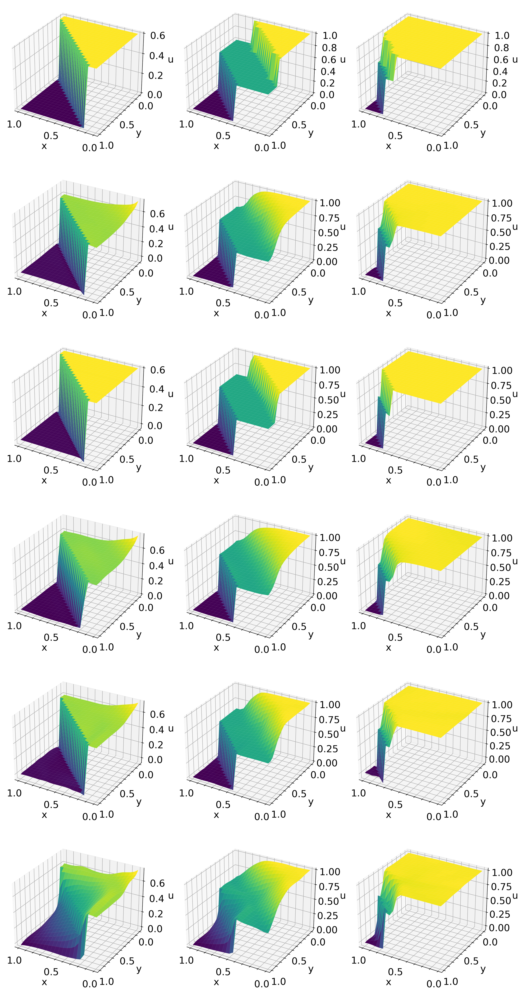

[Saved] evaluation\burgers2d\paper_figures\Figure20_rows6_part2.png


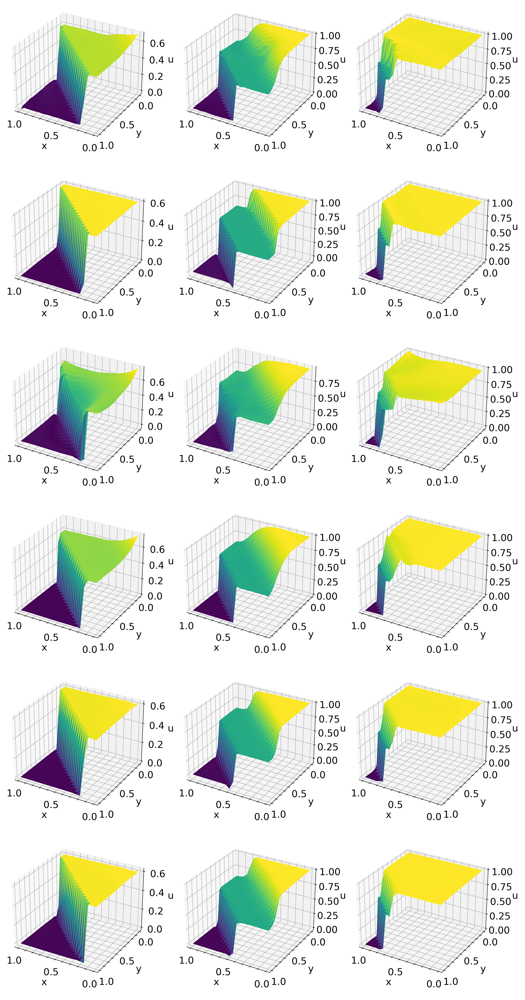

In [ ]:
"""Arrange evaluation PNGs using an editable row-by-row LAYOUT.
Install: pip install pillow
Run from the project directory: python assemble_guckenheimer_figure.py
No panel letters, model names, or time headings are added.
PDF embeds raster images; it does not convert them into vector plots.
"""
from pathlib import Path
import csv
import re
from PIL import Image, ImageChops
from IPython.display import display, Image as NotebookImage

EVALUATION_ROOT = Path("evaluation/burgers2d")
SEED = None
REFERENCE_METHOD = "Conventional"
TIMES = (0.0, 0.5, 1.0)
OUTPUT_DIR = EVALUATION_ROOT / "paper_figures"
OUTPUT_NAME = "Figure20_selected_seeds"

CELL_WIDTH = 1000
CELL_HEIGHT = 900
COLUMN_GAP = 20
ROW_GAP = 90
OUTER_MARGIN = 35
DPI = 300
ROW_ALIGN = "center"
COLUMN_GAPS = {}
ROW_GAPS = {}
CROP_WHITE_MARGIN = True
WHITE_TOLERANCE = 8
CROP_PADDING = 14
SCALE_MODE = "common"
ALLOW_UPSCALE = False

ROWS_PER_BLOCK = 6
BLOCK_GAP = 150
PREVIEW_WIDTH = 1200
FILE_PREFIX = "Figure20"

def panel(method, time, kind="prediction", seed=None):
    """One evaluation image; seed=None uses SEED (auto-select @ when SEED=None). kind: prediction/reference."""
    return dict(method=method, time=time, kind=kind, seed=seed)

def series(method, times=None, kind="prediction", seed=None):
    """A row segment; change TIMES once to update every default segment."""
    return [panel(method, t, kind, seed) for t in (TIMES if times is None else times)]

def method_directory(root, name):
    exact = root / name
    if exact.is_dir():
        return exact
    matches = [p for p in root.iterdir() if p.is_dir() and p.name.lower() == name.lower()]
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Method folder missing or ambiguous: {exact}")

def select_seed_directory(root, method, seed=None):
    method_dir = method_directory(root, method)
    candidates = []
    for directory in method_dir.iterdir():
        if not directory.is_dir():
            continue
        match = re.fullmatch(r"seed(\d+)", directory.name.replace("@", "").strip(), flags=re.IGNORECASE)
        if match is None:
            continue
        number = int(match.group(1))
        if (seed is None and "@" in directory.name) or (seed is not None and number == int(seed)):
            candidates.append((number, directory))
    if len(candidates) != 1:
        request = "one @-marked seed folder" if seed is None else f"one folder for seed{seed}"
        raise FileNotFoundError(
            f"Expected {request}; found {len(candidates)}.\n"
            f"Method folder: {method_dir}\nCandidates: {[p.name for _, p in candidates]}"
        )
    return candidates[0]

def find_surface(root, method, seed, time, kind):
    actual_seed, seed_dir = select_seed_directory(root, method, seed)
    directory = seed_dir / f"{kind}_surface"
    tag = f"{time:.6f}".replace(".", "p")
    matches = sorted(directory.glob(f"*_seed{actual_seed}_t{tag}.png"))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one surface for t={time:g}; found {len(matches)}.\n"
            f"Folder: {directory}\nPattern: *_seed{actual_seed}_t{tag}.png"
        )
    return matches[0]

def load_surface(path):
    with Image.open(path) as source:
        rgba = source.convert("RGBA")
        white = Image.new("RGBA", rgba.size, "white")
        white.alpha_composite(rgba)
        image = white.convert("RGB")
    if CROP_WHITE_MARGIN:
        difference = ImageChops.difference(image, Image.new("RGB", image.size, "white"))
        channels = difference.split()
        mask = ImageChops.lighter(ImageChops.lighter(channels[0], channels[1]), channels[2])
        box = mask.point(lambda value: 255 if value > WHITE_TOLERANCE else 0).getbbox()
        if box is None:
            raise ValueError(f"Blank surface image: {path}")
        x0, y0, x1, y1 = box
        box = (max(0, x0-CROP_PADDING), max(0, y0-CROP_PADDING),
               min(image.width, x1+CROP_PADDING), min(image.height, y1+CROP_PADDING))
        image = image.crop(box)
    return image

def main(root=None, output_dir=None, layout=None):
    root = Path(EVALUATION_ROOT if root is None else root)
    output_dir = Path(OUTPUT_DIR if output_dir is None else output_dir)
    layout = LAYOUT if layout is None else layout
    if min(CELL_WIDTH, CELL_HEIGHT, DPI) <= 0 or min(COLUMN_GAP, ROW_GAP, OUTER_MARGIN) < 0:
        raise ValueError("Invalid image size, resolution, or spacing.")
    if any(v < 0 for v in (*COLUMN_GAPS.values(), *ROW_GAPS.values())):
        raise ValueError("Gaps must be non-negative.")
    if SCALE_MODE not in ("common", "fit"):
        raise ValueError("SCALE_MODE must be common or fit.")
    rows = []
    for row in layout:
        cells = row["cells"] if isinstance(row, dict) else row
        align = row.get("align", ROW_ALIGN) if isinstance(row, dict) else ROW_ALIGN
        if align not in ("left", "center", "right") or not cells:
            raise ValueError("Each row needs cells and a valid alignment.")
        rows.append((cells, align))
    if not rows:
        raise ValueError("LAYOUT is empty.")

    def row_width(cells):
        return len(cells)*CELL_WIDTH + sum(COLUMN_GAPS.get(c, COLUMN_GAP) for c in range(len(cells)-1))

    entries = []
    for r, (cells, _) in enumerate(rows):
        for c, item in enumerate(cells):
            if item is None:
                continue
            if isinstance(item, (str, Path)):
                path = Path(item)
                info = dict(method="", time="", seed="", kind="explicit")
            else:
                info = dict(item)
                requested_seed = SEED if info.get("seed") is None else info["seed"]
                info["seed"], seed_dir = select_seed_directory(root, info["method"], requested_seed)
                path = find_surface(root, info["method"], info["seed"], info["time"], info.get("kind", "prediction"))
            if not path.is_file():
                raise FileNotFoundError(path)
            entries.append((r, c, info, path))
    if not entries:
        raise ValueError("LAYOUT contains no images.")
    dimensions = [load_surface(path).size for _, _, _, path in entries]
    common_scale = min(CELL_WIDTH/max(w for w, h in dimensions), CELL_HEIGHT/max(h for w, h in dimensions))
    if not ALLOW_UPSCALE:
        common_scale = min(1.0, common_scale)
    content_width = max(row_width(cells) for cells, _ in rows)
    width = 2*OUTER_MARGIN + content_width
    height = 2*OUTER_MARGIN + len(rows)*CELL_HEIGHT + sum(ROW_GAPS.get(r, ROW_GAP) for r in range(len(rows)-1))
    canvas = Image.new("RGB", (width, height), "white")
    for r, c, info, path in entries:
        cells, align = rows[r]
        extra = content_width-row_width(cells)
        shift = {"left": 0, "center": extra//2, "right": extra}[align]
        x = OUTER_MARGIN+shift+c*CELL_WIDTH+sum(COLUMN_GAPS.get(k, COLUMN_GAP) for k in range(c))
        y = OUTER_MARGIN+r*CELL_HEIGHT+sum(ROW_GAPS.get(k, ROW_GAP) for k in range(r))
        image = load_surface(path)
        scale = common_scale if SCALE_MODE == "common" else min(CELL_WIDTH/image.width, CELL_HEIGHT/image.height)
        if not ALLOW_UPSCALE:
            scale = min(1.0, scale)
        size = (max(1, round(image.width*scale)), max(1, round(image.height*scale)))
        image = image.resize(size, Image.Resampling.LANCZOS)
        canvas.paste(image, (x+(CELL_WIDTH-image.width)//2, y+(CELL_HEIGHT-image.height)//2))
    output_dir.mkdir(parents=True, exist_ok=True)
    png_path = output_dir / f"{OUTPUT_NAME}.png"
    canvas.save(png_path, dpi=(DPI, DPI))

    with (output_dir / f"{OUTPUT_NAME}_sources.csv").open(
        "w", newline="", encoding="utf-8-sig"
    ) as stream:
        writer = csv.writer(stream)
        writer.writerow(("row", "column", "method", "time", "seed", "kind", "source"))
        writer.writerows(
            (r + 1, c + 1, info.get("method", ""), info.get("time", ""),
             info.get("seed", ""), info.get("kind", "prediction"), str(path))
            for r, c, info, path in entries
        )

    print(f"[Saved] {png_path}")
    return png_path

MODEL_ROWS = [
    series(REFERENCE_METHOD, kind="reference"),
    series("Conventional"),
    series("NTK"),
    series("SA"),
    series("Causal"),
    series("rba"),
    series("brdr"),
    series("aSA"),
    series("SLFormer_Single(NoSlope)"),
    series("SLFormer(NoSlope)"),
    series("SLFormer_Single"),
    series("SLFormer"),
]

if not isinstance(ROWS_PER_BLOCK, int) or ROWS_PER_BLOCK < 1:
    raise ValueError("ROWS_PER_BLOCK must be a positive integer.")

COLUMN_GAPS = {}
ROW_GAPS = {}

for part, start in enumerate(
    range(0, len(MODEL_ROWS), ROWS_PER_BLOCK), start=1
):
    layout = MODEL_ROWS[start:start + ROWS_PER_BLOCK]
    OUTPUT_NAME = f"{FILE_PREFIX}_rows{ROWS_PER_BLOCK}_part{part}"

    png_path = main(layout=layout)
    display(NotebookImage(filename=str(png_path), width=PREVIEW_WIDTH))
